## Importation data

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
BASE = "https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/"
full = pd.read_csv(BASE + "training_data.csv")
test = pd.read_csv(BASE + "testing_data.csv") # scellé jusqu&#39;à la Partie F

full["id"], test["id"] = range(len(full)), range(len(test))
train, val = train_test_split(full, test_size=0.10, random_state=42,stratify=full["sarcasm"])
train = train.reset_index(drop=True).copy()
val = val.reset_index(drop=True).copy()

## Visualisation Data

In [10]:
train.head(30)

,tweet,sarcasm,sentiment,dialect,id
0,"""#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن ال...",False,NEU,msa,2474
1,"""RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يري...",False,NEU,msa,12107
2,تحدثنا عن هذا الكتاب الجميل عن خروج المصريين ع...,False,NEU,msa,2135
3,"""RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الد...",True,NEG,msa,640
4,"""أوباما يلاحق محمد بن سلمان !!: https://t.co/x...",False,NEU,msa,6766
5,"""تبرعات الهلال الاحمر الكويتي لن تسلم للهلال ا...",False,NEU,msa,5267
6,"""@riyadhalasaad عندما نشاهد مايجري في سوريا من...",False,NEG,msa,1318
7,"""يوسف سونة : دونالد ترامب و هيلاري كلينتون من ...",False,NEU,msa,10003
8,بموت ضحك عطو فرصه لغيركم يحزن,False,NEG,msa,4557
9,في قلبي رجل M❤️ يلغ...,False,POS,msa,49


In [11]:
test.head(30)

,tweet,sarcasm,sentiment,dialect,id
0,اخوي حانق يالغلا وشفيك معصب؟ عادي تراهم بشر يف...,False,NEG,msa,0
1,اف مو متعوده عليهم سته https://t.co/8igFPx1i26,True,NEG,msa,1
2,اللهم اشفِ مرضانا ومرضى المسلمين . . ♥️,False,POS,msa,2
3,ابشركم طلقت السات 😘.,False,POS,gulf,3
4,مؤشر خطير: ٩٠٪ من الشخصيات البرلمانية في الكوي...,True,NEG,msa,4
5,مكتوب للغايب يوم هيعود❤❤اللهم لك الحمد حاسه رو...,False,POS,msa,5
6,اختطاف الأطفال في #الجزائر..العثور على جثة مشو...,False,NEU,msa,6
7,سقف الطموحات المستقبليه بتبقى عاليه ف وقت دراس...,True,NEG,msa,7
8,خرجك ، من قال لك تقول رأيك يحرية ؟ شو ما سمعت ...,False,NEU,msa,8
9,نحن في هذه الحياةإماأن نكونقدوةأوعبرة فقيمتنال...,False,NEU,msa,9


,feature,count,percentage
0,url,4801,38.261077
1,mention,2883,22.975773
2,hashtag,5771,45.991393
3,laugh,201,1.601849
4,repeated_punct,2231,17.779726
5,repeated_letter,652,5.196047
6,latin,6972,55.562639
7,indian_digit,305,2.430666
8,csv_quote_wrap,7617,60.702901
9,tatweel,571,4.550526


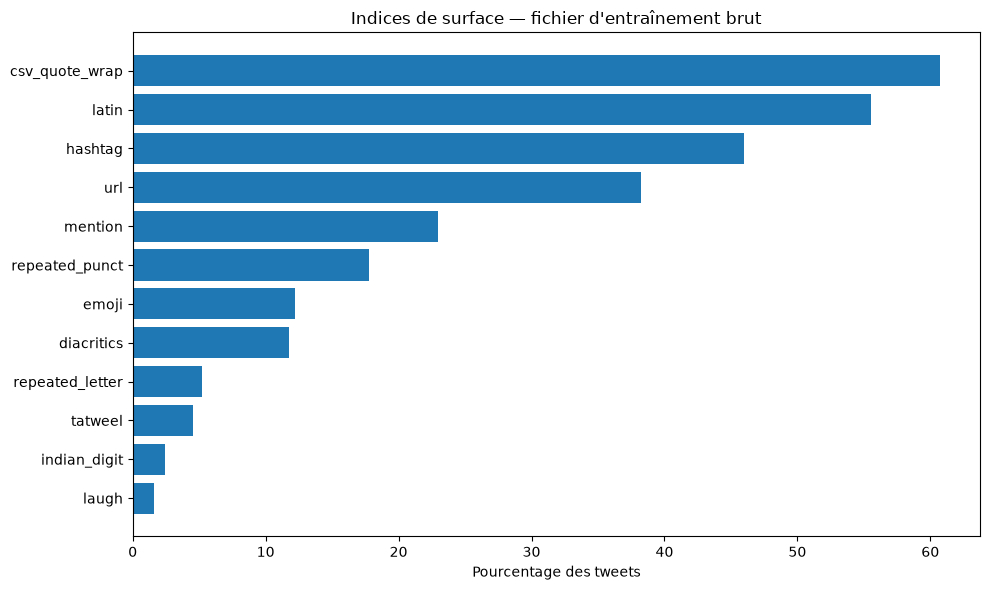

In [16]:
import re
import emoji
from pyarabic.araby import TATWEEL,DIACRITICS
import matplotlib.pyplot as plt



URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
MENTION_RE = re.compile(r"(?<!\w)@\w+")
HASHTAG_RE = re.compile(r"(?<!\w)#\w+")
LAUGH_RE = re.compile(r"ه{2,}")
REPEATED_PUNCT_RE = re.compile(r"([!?؟.,،؛…])\1+")
REPEATED_LETTER_RE = re.compile(r"([^\W\d_])\1{2,}")
LATIN_RE = re.compile(r"[A-Za-z]")
INDIAN_DIGIT_RE = re.compile(r"[٠-٩]")
DIACRITIC_CHARS = "".join(ch for ch in DIACRITICS if ch != TATWEEL)
DIACRITIC_RE = re.compile("[" + re.escape(DIACRITIC_CHARS) + "]")
TATWEEL_RE = re.compile(re.escape(TATWEEL))


def has_emoji(text):
    return len(emoji.emoji_list(str(text))) > 0

def has_csv_quote_wrap(text):
    stripped = str(text).strip()
    return len(stripped) >= 2 and stripped[0] == '"' and stripped[-1] == '"'

CUES = [
    ("url", lambda text: bool(URL_RE.search(text))),
    ("mention", lambda text: bool(MENTION_RE.search(text))),
    ("hashtag", lambda text: bool(HASHTAG_RE.search(text))),
    ("laugh", lambda text: bool(LAUGH_RE.search(text))),
    ("repeated_punct", lambda text: bool(REPEATED_PUNCT_RE.search(text))),
    ("repeated_letter", lambda text: bool(REPEATED_LETTER_RE.search(text))),
    ("latin", lambda text: bool(LATIN_RE.search(text))),
    ("indian_digit", lambda text: bool(INDIAN_DIGIT_RE.search(text))),
    ("csv_quote_wrap", has_csv_quote_wrap),
    ("tatweel", lambda text: bool(TATWEEL_RE.search(text))),
    ("diacritics", lambda text: bool(DIACRITIC_RE.search(text))),
    ("emoji", has_emoji),
]

tweets = full["tweet"].astype(str)

rows = []
for name, function in CUES:
    present = tweets.map(function).astype(bool)
    rows.append(
        {
            "feature": name,
            "count": present.sum(),
            "percentage": 100 * present.mean(),
        }
    )

audit = pd.DataFrame(rows)
display(audit)

fig, ax = plt.subplots(figsize=(10, 6))
order = audit.sort_values("percentage", ascending=True)
ax.barh(order["feature"], order["percentage"])
ax.set_xlabel("Pourcentage des tweets")
ax.set_title("Indices de surface — fichier d'entraînement brut")
fig.tight_layout()
display(fig)
plt.close(fig)



In [ ]:
print(train["dialect"].unique())
print(train["sentiment"].unique())

<ArrowStringArray>
['msa', 'egypt', 'levant', 'gulf', 'magreb']
Length: 5, dtype: str
<ArrowStringArray>
['NEU', 'NEG', 'POS']
Length: 3, dtype: str


## Exploration de data

In [29]:
import matplotlib.pyplot as plt 
import seaborn as sns

dialect_order = ['msa', 'egypt', 'levant', 'gulf', 'magreb']
sentiment_order = ['NEG', 'NEU', 'POS']



### Pourcentage de sarcasme par dialecte

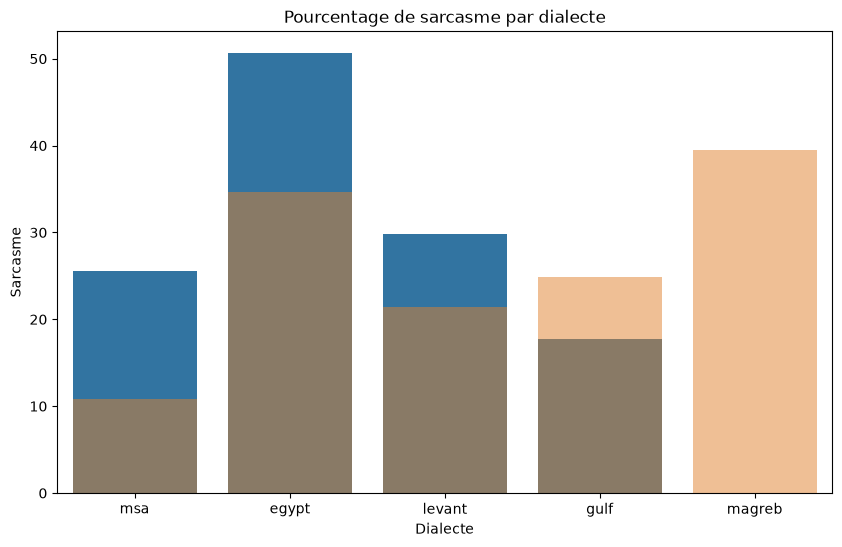

In [ ]:
df_sar_dialect_train = train.groupby('dialect')['sarcasm'].value_counts(normalize=True).unstack() * 100
df_sar_dialect_test = test.groupby('dialect')['sarcasm'].value_counts(normalize=True).unstack() * 100
plt.figure(figsize=(10, 6))
sns.barplot(data=df_sar_dialect_test.reset_index(), x='dialect', y=1, order=dialect_order)
sns.barplot(data=df_sar_dialect_train.reset_index(), x='dialect', y=1, order=dialect_order, alpha=0.5)
plt.title("Pourcentage de sarcasme par dialecte")
plt.xlabel("Dialecte")
plt.ylabel("Sarcasme")
plt.show()



### Pourcentage de sarcasme par sentiment.

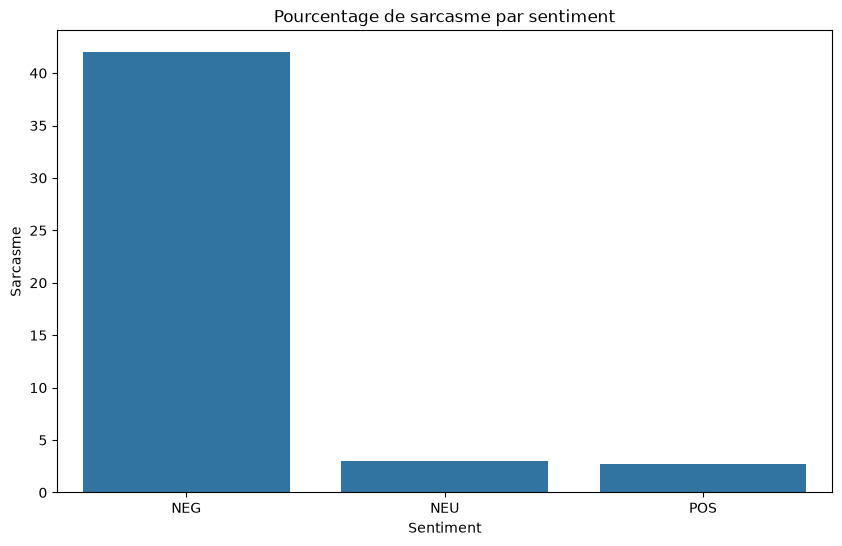

In [30]:
df_sar_sentiment = train.groupby('sentiment')['sarcasm'].value_counts(normalize=True).unstack() * 100
plt.figure(figsize=(10, 6))
sns.barplot(data=df_sar_sentiment.reset_index(), x='sentiment', y=1, order=sentiment_order)
plt.title("Pourcentage de sarcasme par sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Sarcasme")
plt.show()
